In [10]:
import os
from dotenv import load_dotenv
load_dotenv()

from langchain.chat_models import init_chat_model
from langchain_core.documents import Document
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langgraph.graph import StateGraph,START,END
from pydantic import BaseModel,Field
from langchain_core.messages import AIMessage,HumanMessage,SystemMessage

In [11]:
if os.environ.get("OPENAI_API_KEY"):
    api_key = os.environ.get("OPENAI_API_KEY")
    print("API Key is all set!!")
else:
    raise ValueError("API Key not present!!")

API Key is all set!!


In [12]:
llm  = init_chat_model("gpt-5-nano",temperature = 0)

In [19]:
from typing import TypedDict,List,Annotated
from operator import add

class graph_schema(TypedDict):
    messages_manual: List
    messages_auto: Annotated[List,add]






In [20]:
def create_post(state:graph_schema)->graph_schema:
    
    messages_manual = state['messages_manual']
    response_manual = llm.invoke(messages_manual).content
    response_manual_ai = AIMessage(content=response_manual)
    state['messages_manual']= messages_manual + [response_manual_ai]

    messages_auto = state['messages_auto']
    response_auto = llm.invoke(messages_auto).content
    response_auto_ai = AIMessage(content=response_auto)
    state['messages_auto'] = [response_auto_ai]
    return state

def curated_post(state:graph_schema)->graph_schema:
    messages_manual = state['messages_manual']
    response_manual = llm.invoke(messages_manual).content
    response_manual_ai = AIMessage(content=response_manual)
    state['messages_manual']= messages_manual + [response_manual_ai]

    messages_auto = state['messages_auto']
    response_auto = llm.invoke(messages_auto).content
    response_auto_ai = AIMessage(content=response_auto)
    state['messages_auto'] = [response_auto_ai]
     
    return state




In [21]:
from langgraph.graph import StateGraph,START,END

graph = StateGraph(graph_schema)

graph.add_node("create_post",create_post)
graph.add_node("curated_post",curated_post)

graph.add_edge(START,"create_post")
graph.add_edge("create_post","curated_post")
graph.add_edge("curated_post",END)

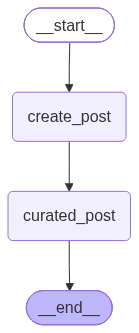

In [22]:
from IPython.display import Image,display

messages_graph  = graph.compile()

Image(messages_graph.get_graph().draw_mermaid_png())

In [23]:
messages_graph.invoke({"messages_manual":[HumanMessage(content="what is databricks?")],"messages_auto":[HumanMessage(content="what is databricks?")]})

{'messages_manual': [HumanMessage(content='what is databricks?', additional_kwargs={}, response_metadata={}),
  AIMessage(content='Databricks is a cloud-based platform that unifies data engineering, data science, and analytics in a single environment. It’s built around Apache Spark and runs on major clouds (AWS, Azure, GCP). It combines a collaborative notebook workspace with managed Spark clusters and a suite of tools to build, run, and govern data and ML workflows.\n\nKey components and features:\n- Unified workspace: notebooks (Python, SQL, Scala, R) for data engineering, analytics, and experimentation.\n- Managed Spark clusters and Databricks Runtime: autoscaling, performance optimizations, and simplified cluster management.\n- Delta Lake: a storage layer on top of data lakes that provides ACID transactions and reliable data quality.\n- Databricks SQL: SQL-based analytics and dashboards for business intelligence.\n- MLflow: ML lifecycle tooling for experiment tracking, models, and 